# 01 · ¿Qué tan rápido va un F1 en cada parte del circuito?

Este notebook responde esa pregunta con la **vuelta de la pole de Monza 2024**: dónde va a fondo, dónde frena y a qué velocidad entra y sale de cada curva.

Los datos vienen de [OpenF1](https://openf1.org) y el análisis vive en `f1analytics.analisis.circuito`; este notebook solo lo usa y lo dibuja. Es la misma lógica que después sirve la web.

> Necesita internet y que no haya una sesión de F1 en vivo (OpenF1 bloquea entonces las consultas sin clave). La primera ejecución tarda unos segundos; después la sesión queda en caché en disco.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from f1analytics.analisis.circuito import (
    orientar_circuito,
    posicion_curvas,
    resumen_circuito,
    zonas_alta_velocidad,
    zonas_frenado,
)
from f1analytics.datos.cargador import Cargador
from f1analytics.datos.circuitos import circuito
from f1analytics.datos.cliente import ClienteOpenF1
from f1analytics.datos.telemetria_vuelta import telemetria_de_vuelta, vuelta_rapida
from f1analytics.graficos.circuito import mapa_marchas, mapa_velocidad
from f1analytics.graficos.estilo import aplicar_estilo

aplicar_estilo()
pd.options.display.float_format = "{:,.1f}".format
CARPETA_FIGURAS = Path("../../docs/figuras")  # las figuras del README

cargador = Cargador(ClienteOpenF1())

## 1. La sesión y la vuelta

Se busca la clasificación del Gran Premio de Italia 2024 y, entre todas las vueltas válidas (sin salidas de pits), la más rápida: la de la pole.

In [2]:
ANIO = 2024
calendario = cargador.calendario(ANIO)
evento = int(calendario.loc[calendario["circuito"] == "Monza", "evento"].iloc[0])
sesion = cargador.buscar_sesion(ANIO, evento, "Qualifying")

vueltas = cargador.vueltas(sesion)
validas = vueltas[vueltas["tiempo_vuelta_s"].notna() & ~vueltas["salida_pits"]]
mejor = validas.loc[validas["tiempo_vuelta_s"].idxmin()]
numero_piloto, numero_vuelta = int(mejor["piloto"]), int(mejor["vuelta"])

# Comprobación cruzada con la función que usa la API.
assert vuelta_rapida(cargador, sesion, numero_piloto) == numero_vuelta

pilotos = cargador.pilotos(sesion).set_index("numero")
piloto = pilotos.loc[numero_piloto]
minutos, segundos = divmod(mejor["tiempo_vuelta_s"], 60)
etiqueta = f"{piloto['codigo']} · Monza {ANIO} · {int(minutos)}:{segundos:06.3f}"
print(f"Sesión {sesion}: pole de {piloto['nombre']} ({piloto['equipo']}), vuelta {numero_vuelta}")
print(etiqueta)

Sesión 9586: pole de Lando NORRIS (McLaren), vuelta 11
NOR · Monza 2024 · 1:19.327


## 2. La telemetría

`telemetria_de_vuelta` une la velocidad, el freno, el acelerador y la marcha del coche (`car_data`) con su posición en la pista (`location`) y calcula la distancia recorrida.

In [3]:
tel = telemetria_de_vuelta(cargador, sesion, numero_piloto, numero_vuelta)
duracion_s, recorrido_m = tel["tiempo_s"].iloc[-1], tel["distancia_m"].iloc[-1]
print(f"{len(tel)} muestras en {duracion_s:.1f} s; {recorrido_m:,.0f} m recorridos")
tel.head()

306 muestras en 79.0 s; 5,719 m recorridos


,tiempo_s,distancia_m,x,y,velocidad,acelerador,freno,marcha,rpm,drs
0,0.1,0.0,-1359,-498,321,99,0,8,11334,14
1,0.3,17.9,-1348,-374,322,99,0,8,11378,14
2,0.6,46.6,-1314,2,325,99,0,8,11457,14
3,1.0,82.9,-1298,182,328,99,0,8,11542,14
4,1.4,115.8,-1256,673,330,99,0,8,11615,14


## 3. El mapa, girado como en la transmisión

OpenF1 no trae los números de curva ni cómo se muestra el mapa en la TV. Eso sale de `circuitos.json` (una copia estática de [MultiViewer](https://multiviewer.app)): se gira la pista y las curvas con la **misma** rotación para que sigan coincidiendo.

In [4]:
clave_circuito = int(calendario.loc[calendario["evento"] == evento, "circuito_clave"].iloc[0])
trazado = circuito(clave_circuito, ANIO)
print(f"{trazado.nombre}: {len(trazado.curvas)} curvas, rotación de {trazado.rotacion}°")

tel_girada = orientar_circuito(tel, trazado.rotacion)
curvas = posicion_curvas(trazado.curvas, trazado.rotacion)
frenadas = zonas_frenado(tel_girada, curvas)
resumen = resumen_circuito(tel, frenadas)

Monza: 11 curvas, rotación de 95°


## 4. Velocidad en cada parte de la pista

Azul es lento, amarillo medio y naranja rápido. Los rombos marcan dónde empieza cada frenada.

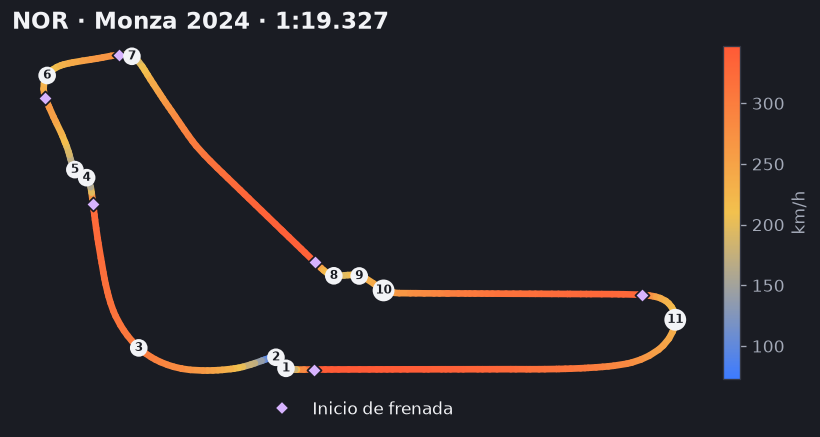

In [5]:
fig = mapa_velocidad(tel_girada, curvas, frenadas, titulo=etiqueta)
fig.savefig(CARPETA_FIGURAS / "circuito-velocidad.png", bbox_inches="tight")
plt.show()

## 5. La marcha engranada

Cada color es una marcha. Se ve que en Monza se pasa casi toda la vuelta en séptima y octava: es el circuito de menos carga aerodinámica del calendario.

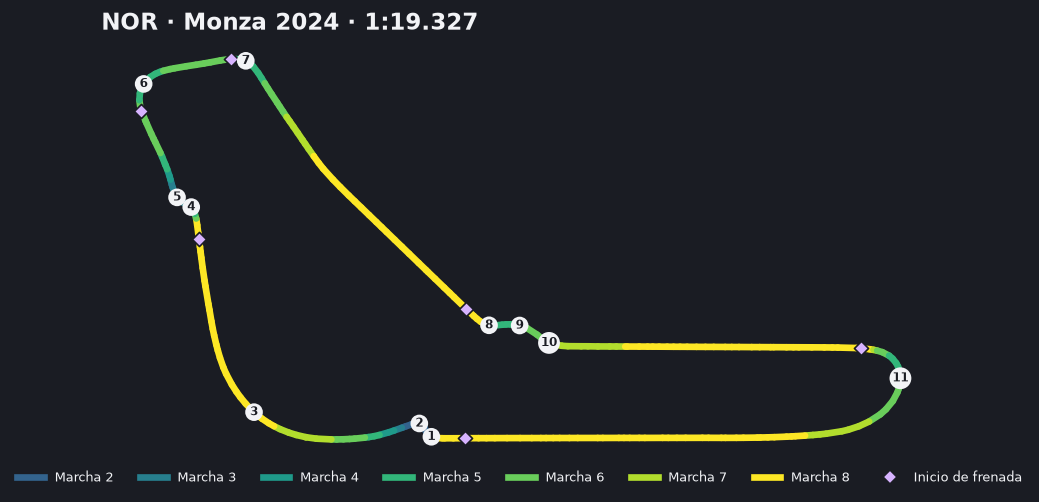

In [6]:
fig = mapa_marchas(tel_girada, curvas, frenadas, titulo=etiqueta)
fig.savefig(CARPETA_FIGURAS / "circuito-marchas.png", bbox_inches="tight")
plt.show()

## 6. Las frenadas

Una fila por curva donde se frena: dónde empieza, cuánto dura y a qué velocidad entra y sale.

In [7]:
tabla = frenadas.assign(
    curva=lambda t: t["curva"].astype(str) + t["letra"],
    perdida_kmh=lambda t: t["vel_entrada"] - t["vel_salida"],
)[["curva", "inicio_m", "longitud_m", "vel_entrada", "vel_salida", "perdida_kmh"]]
tabla

,curva,inicio_m,longitud_m,vel_entrada,vel_salida,perdida_kmh
0,1,774.3,115.5,319.0,94.0,225.0
1,4,"1,980.4",100.3,317.0,124.0,193.0
2,6,"2,411.5",51.6,263.0,229.0,34.0
3,7,"2,757.9",28.1,248.0,212.0,36.0
4,8,"3,815.9",49.2,296.0,215.0,81.0
5,11,"5,007.4",65.2,307.0,239.0,68.0


## 7. Las rectas

Los tramos en que la velocidad supera el percentil 90 de la vuelta.

In [8]:
zonas_alta_velocidad(tel_girada)[["inicio_m", "fin_m", "longitud_m", "vel_maxima"]]

,inicio_m,fin_m,longitud_m,vel_maxima
0,230.6,744.9,514.3,347.0
1,"3,574.2","3,791.4",217.2,338.0


## 8. Conclusión

`resumen_circuito` devuelve solo datos; la web los convierte en una frase en español o en inglés. Aquí se arma una a mano.

In [9]:
frenada = resumen["frenada_mas_fuerte"]
vmax, vmin = resumen["vel_maxima"], resumen["vel_minima"]
print(f"A fondo el {resumen['pct_a_fondo']:.0f} % de la vuelta.")
print(f"Velocidad máxima: {vmax['kmh']:.0f} km/h, a los {vmax['distancia_m']:,.0f} m de la meta.")
print(f"Velocidad mínima: {vmin['kmh']:.0f} km/h, a los {vmin['distancia_m']:,.0f} m.")
print(
    f"Frenada más fuerte: curva {frenada['curva']}{frenada['letra']}, "
    f"de {frenada['vel_entrada']:.0f} a {frenada['vel_salida']:.0f} km/h."
)
resumen

A fondo el 83 % de la vuelta.
Velocidad máxima: 347 km/h, a los 653 m de la meta.
Velocidad mínima: 73 km/h, a los 935 m.
Frenada más fuerte: curva 1, de 319 a 94 km/h.


{'pct_a_fondo': 83.08429173577966,
 'vel_maxima': {'kmh': 347.0, 'distancia_m': 652.704861111111},
 'vel_minima': {'kmh': 73.0, 'distancia_m': 935.2636111111112},
 'frenada_mas_fuerte': {'curva': 1,
  'letra': '',
  'vel_entrada': 319.0,
  'vel_salida': 94.0}}